Pobranie i wrzucenie zdjęć do tablicy, do dalszych działań 

In [ ]:
import matplotlib.pyplot as plt
import cv2
import urllib.request
import numpy as np

urls = [
    'https://upload.wikimedia.org/wikipedia/commons/c/c8/A_pity_it%27s_so_regular_-_geograph.org.uk_-_3006545.jpg',
    'https://upload.wikimedia.org/wikipedia/commons/5/51/Departing_for_the_Ganges_boat_trip_%285104780821%29.jpg?utm_source=commons.wikimedia.org&utm_campaign=index&utm_content=original',
    # 'https://commons.wikimedia.org/wiki/File:Santo_Domingo_Mérida.jpg',
    'https://upload.wikimedia.org/wikipedia/commons/6/67/Overexposed_photo.JPG?utm_source=commons.wikimedia.org&utm_campaign=index&utm_content=original'
]
results = []

for url in urls:
    req = urllib.request.Request(
        url, 
        headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}
    )
    with urllib.request.urlopen(req) as resp:
        image = np.asarray(bytearray(resp.read()), dtype=np.uint8)
    img = cv2.imdecode(image, cv2.IMREAD_COLOR)
    results.append(img)

# for result in results:
#     plt.imshow(result)
#     plt.show()

Generowanie histogramów

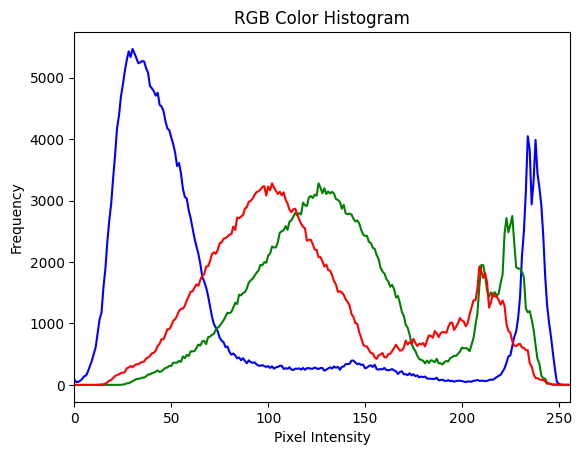

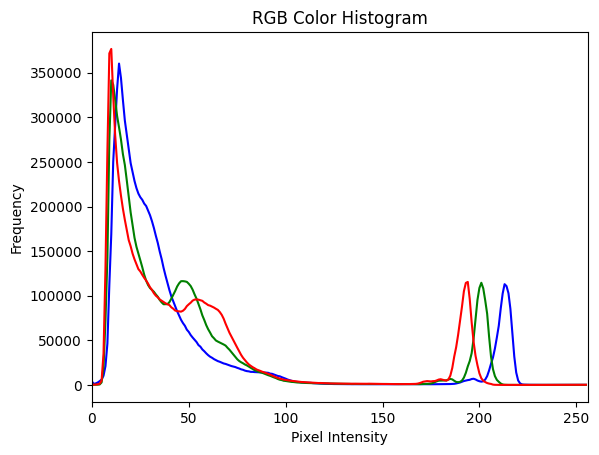

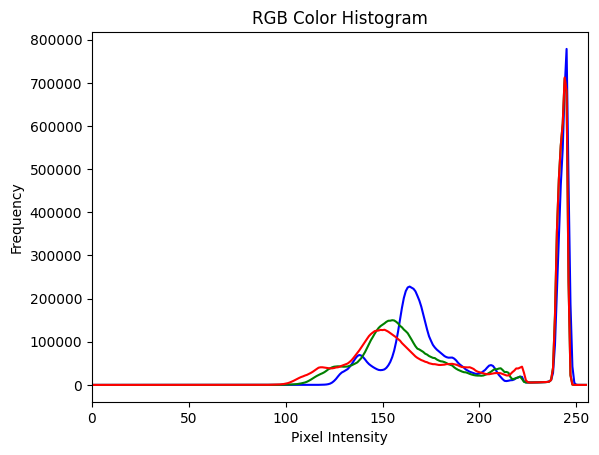

In [ ]:
colors = ('b', 'g', 'r')
for result in results:
    for i, col in enumerate(colors):
        hist = cv2.calcHist([result], [i], None, [256], [0, 256])
        plt.plot(hist, color=col)
        plt.xlim([0, 256])

    # Opis ośi 
    plt.title("RGB Color Histogram")
    plt.xlabel("Pixel Intensity")
    plt.ylabel("Frequency")
    plt.show()

Analiza obrazów pod względem jakości

 Kanał B: uwaga niedoświetelnie / utrata detali w cieniach
 Kanał B: uwaga prześwietlenie / przepalanie jasnych detali


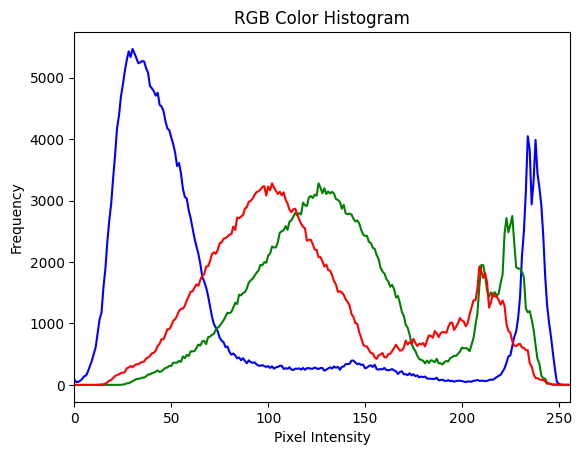

 Kanał B: uwaga niedoświetelnie / utrata detali w cieniach
 Kanał G: uwaga niedoświetelnie / utrata detali w cieniach
 Kanał R: uwaga niedoświetelnie / utrata detali w cieniach


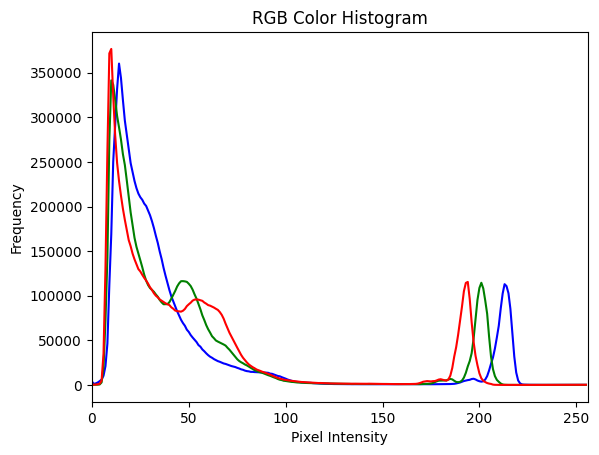

 Kanał B: uwaga prześwietlenie / przepalanie jasnych detali
 Kanał G: uwaga prześwietlenie / przepalanie jasnych detali
 Kanał R: uwaga prześwietlenie / przepalanie jasnych detali


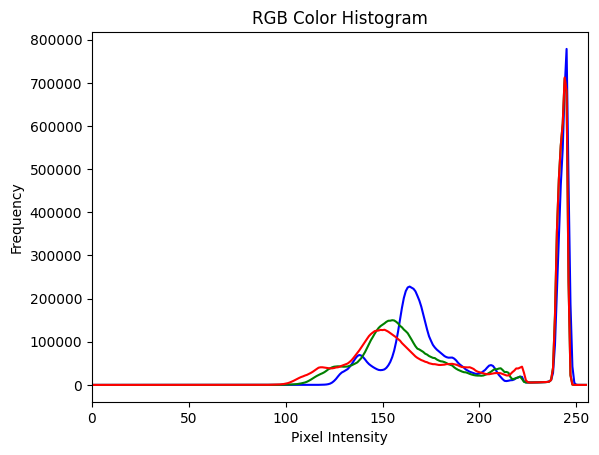

In [28]:
# importujemy do sumowania poszczególnych wartości pixelów np od 0 do 5 dla ciemnych miejsc
import numpy as np
# Generowanie histogramu
colors = ('b', 'g', 'r')
for result in results:
# Obliczenie wszystkiej ilości pixeli do weryfikacji
    result_pixels = result.shape[0] * result.shape[1]
    for i, col in enumerate(colors):
        hist = cv2.calcHist([result], [i], None, [256], [0, 256])
        plt.plot(hist, color=col)

        hist_norm = hist/result_pixels
        # *100 zeby otrzymac wynik w procentach
        # badanie zakresów cieni w przedziale 0-50 i jasnych w przedziale 230-256
        shadows = np.sum(hist_norm[0:50])*100
        brightness = np.sum(hist_norm[230:256])*100

        # Weryfikacja przeciemnienia i przejaśnienia
        if shadows > 10:
            print(f" Kanał {col.upper()}: uwaga niedoświetelnie / utrata detali w cieniach")
        if brightness > 5:
            print(f" Kanał {col.upper()}: uwaga prześwietlenie / przepalanie jasnych detali")
    plt.xlim([0, 256])
    # Opis ośi 
    plt.title("RGB Color Histogram")
    plt.xlabel("Pixel Intensity")
    plt.ylabel("Frequency")
    plt.show()